   
WarmUp
=======

Trend-Seasonal
=======

Differencing
===========

Exponential-smoothing
===================


**Times series course**  
IMT Mines ALES  
2IA



In [1]:
import pandas as pd
import datetime as dt
import matplotlib.pyplot as plt
import numpy as np
plt.rcParams['figure.figsize'] = [15, 5]

In [2]:
df = pd.read_csv('../data/shampoo_sales.csv', parse_dates=True, header=0)
df.Month = df.Month.apply(lambda x: '199' +x )
df.index = pd.to_datetime(df.Month, format='%Y-%m') + pd.offsets.DateOffset(years=4)
df = df.drop(['Month'], axis=1)
df.head()

,Sales
Month,
1995-01-01,266.0
1995-02-01,145.9
1995-03-01,183.1
1995-04-01,119.3
1995-05-01,180.3


In [3]:
data = df.Sales.values.tolist()
print(data[:10])

[266.0, 145.9, 183.1, 119.3, 180.3, 168.5, 231.8, 224.5, 192.8, 122.9]


## Simple exponential smoothing

Implement the simple exponential smoothing from its update equation. Please write a recursive function `simple_es(series, alpha)`.  

Forecast the last value of the time series (as it were unknown).    
Plot it on a graph.

In [ ]:
def simple_es(series: list[float], alpha: float) -> float:
    """Recursive function to calculate simple exponential smoothing"""
    if len(series) == 1:
        return series[0]
    else:
        return ((alpha * series[-1]) + ((1 - alpha) * simple_es(series[:-1], alpha)))

forecast = 551.2, actual = 646.9, error = 95.7


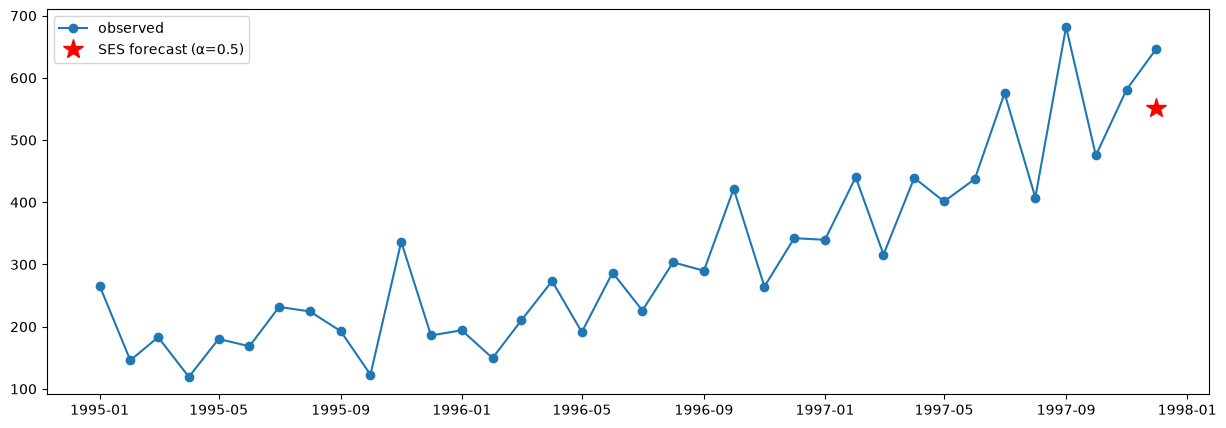

In [5]:
alpha = 0.5
forecast = simple_es(data[:-1], alpha)
actual = data[-1]
print(f"forecast = {forecast:.1f}, actual = {actual:.1f}, error = {actual - forecast:.1f}")

fig, ax = plt.subplots()
ax.plot(df.index, data, marker="o", label="observed")
ax.plot(df.index[-1], forecast, "r*", markersize=15, label=f"SES forecast (α={alpha})")
ax.legend()
plt.show()

### None seasonal Holt-Winters exponential smoothing

Build a recursive function `double_es(series, alpha, beta)` that:
- return a trend using the trend update equation,
- use the `simple_es` function to calculate the level l(n) and l(n-1),
- use data[1] - data[0] as initial trend

Compute the forecasting on the last value.

In [7]:
def double_es(series: list[float], alpha: float, beta: float) -> float:
    """Recursive function to calculate double exponential smoothing"""
    if len(series) < 2:
        raise ValueError("Series must have at least two data points for double exponential smoothing.")
    if len(series) == 2:
        return series[1] - series[0]
    else:
        level_n = simple_es(series, alpha)
        level_n_minus_1 = simple_es(series[:-1], alpha)
        trend_n = beta * (level_n - level_n_minus_1) + (1 - beta) * double_es(series[:-1], alpha, beta)

        return trend_n

In [9]:
alpha, beta = 0.5, 0.5
train = data[:-1]

level = simple_es(train, alpha)
trend = double_es(train, alpha, beta)
forecast_des = level + 1 * trend          # h = 1

print(f"SES forecast    = {simple_es(train, alpha):.1f}")
print(f"Double forecast = {forecast_des:.1f}")
print(f"Actual          = {data[-1]:.1f}")

SES forecast    = 551.2
Double forecast = 569.3
Actual          = 646.9


Create a vector to see the estimation at each time step. Plot the graph. 

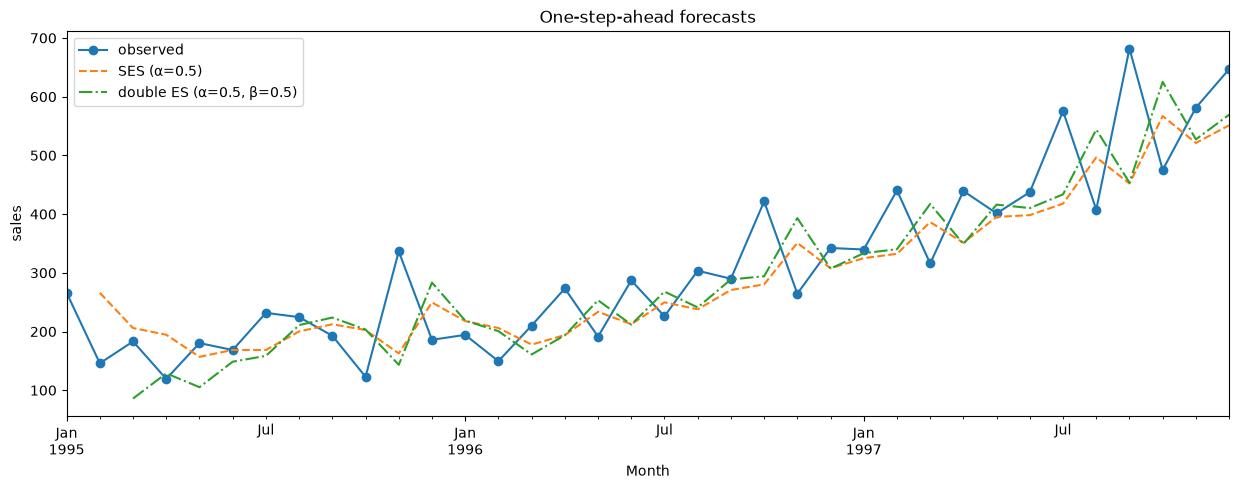

MAE ses: 66.9
MAE double_es: 75.2


In [10]:
alpha, beta = 0.5, 0.5
n = len(data)

# One-step-ahead forecasts: the forecast for position t only uses data[:t].
# SES needs >= 1 past point; double ES needs >= 2 (to define the initial trend).
ses_forecasts = [np.nan] + [simple_es(data[:t], alpha) for t in range(1, n)]
des_forecasts = [np.nan, np.nan] + [
    simple_es(data[:t], alpha) + double_es(data[:t], alpha, beta) for t in range(2, n)
]

estimates = pd.DataFrame(
    {"observed": data, "ses": ses_forecasts, "double_es": des_forecasts},
    index=df.index,
)

fig, ax = plt.subplots()
estimates["observed"].plot(ax=ax, marker="o", label="observed")
estimates["ses"].plot(ax=ax, style="--", label=f"SES (α={alpha})")
estimates["double_es"].plot(ax=ax, style="-.", label=f"double ES (α={alpha}, β={beta})")
ax.set_ylabel("sales")
ax.set_title("One-step-ahead forecasts")
ax.legend()
plt.show()

# Mean absolute error over the common period (from the 3rd point on)
errors = estimates.dropna()
for model in ["ses", "double_es"]:
    mae = (errors["observed"] - errors[model]).abs().mean()
    print(f"MAE {model}: {mae:.1f}")

## Exponential smoothing with built-in functions

In [11]:
from statsmodels.tsa.api import ExponentialSmoothing, SimpleExpSmoothing, Holt

### Simple exponential smoothing

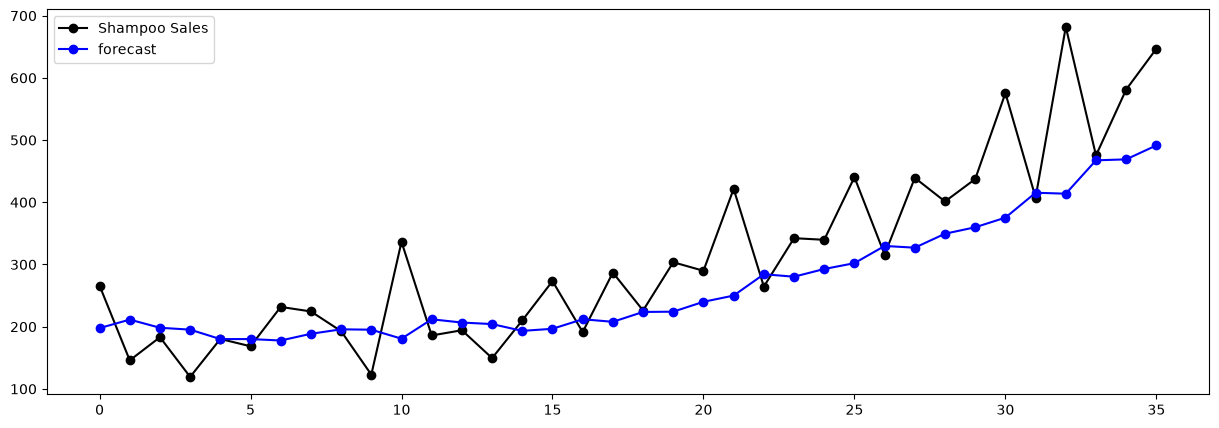

In [12]:
# Explicitly provide alpha to the model
fit1 = SimpleExpSmoothing(data, initialization_method="heuristic").fit(
    smoothing_level=0.2, optimized=False)

plt.plot(data, marker="o", color="black", label='Shampoo Sales')
plt.plot(fit1.fittedvalues, marker="o", color="blue", label='forecast')
plt.legend()
plt.show()

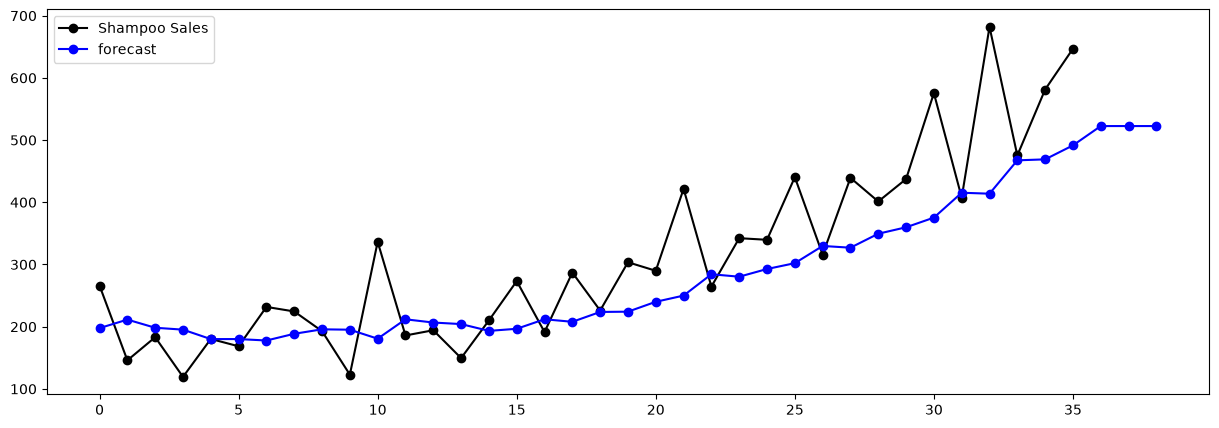

In [13]:
# Make forecasting

forecast = fit1.forecast(3)
full_curve = np.concatenate((fit1.fittedvalues, forecast))

plt.plot(data, marker="o", color="black", label='Shampoo Sales')
plt.plot(full_curve, marker="o", color="blue", label='forecast')
plt.legend()
plt.show()

Use `statsmodel` to provide an optimized value for alpha.

optimized alpha = 0.399
initial level   = 202.8
SSE  (alpha=0.2)  = 299,622
SSE  (optimized)  = 241,615


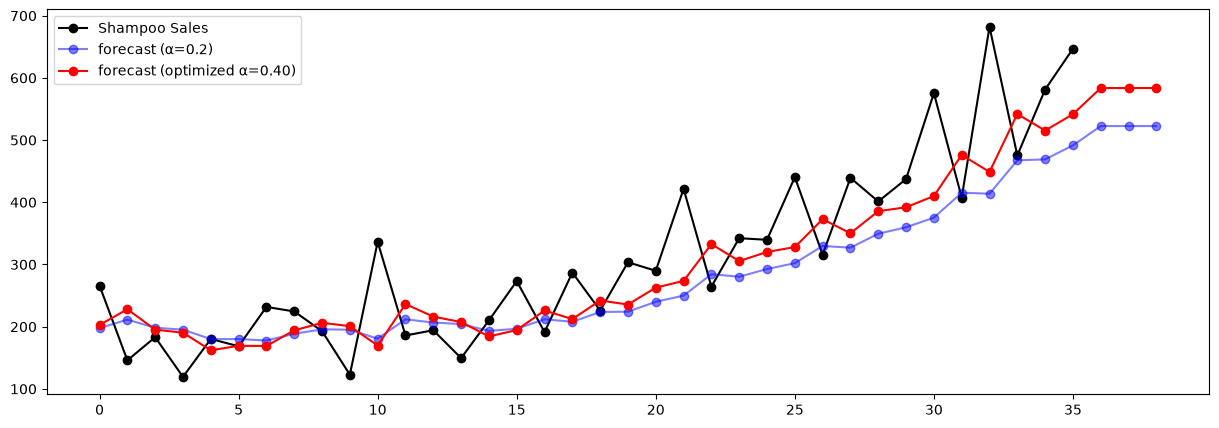

In [14]:
# Let statsmodels optimize alpha (and the initial level) by minimizing the SSE
fit_opt = SimpleExpSmoothing(data, initialization_method="estimated").fit()

alpha_opt = fit_opt.params["smoothing_level"]
print(f"optimized alpha = {alpha_opt:.3f}")
print(f"initial level   = {fit_opt.params['initial_level']:.1f}")
print(f"SSE  (alpha=0.2)  = {fit1.sse:,.0f}")
print(f"SSE  (optimized)  = {fit_opt.sse:,.0f}")

forecast_opt = fit_opt.forecast(3)
full_curve_opt = np.concatenate((fit_opt.fittedvalues, forecast_opt))

plt.plot(data, marker="o", color="black", label="Shampoo Sales")
plt.plot(full_curve, marker="o", color="blue", alpha=0.5, label="forecast (α=0.2)")
plt.plot(full_curve_opt, marker="o", color="red", label=f"forecast (optimized α={alpha_opt:.2f})")
plt.legend()
plt.show()

### None seasonal Holt-Winters exponential smoothing

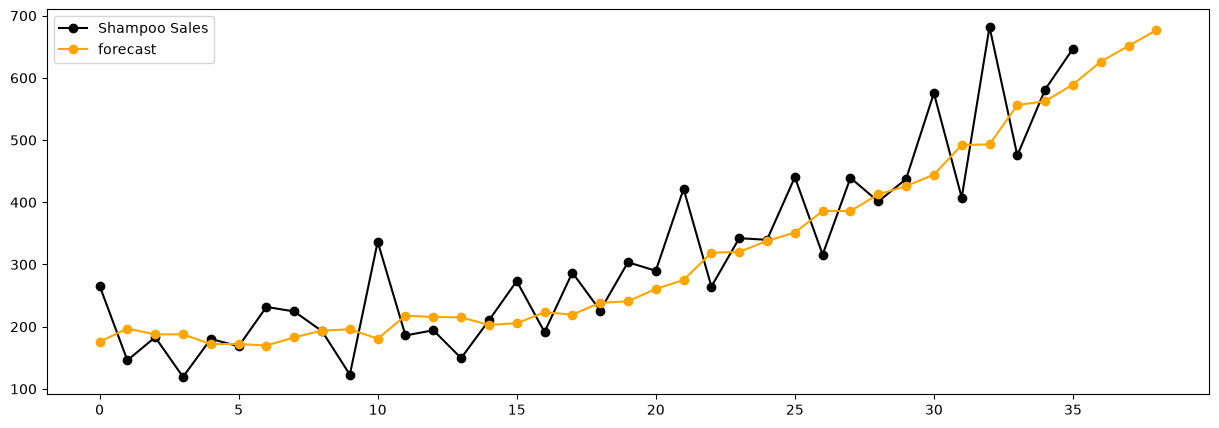

In [15]:
fit1 = Holt(data, initialization_method="estimated").fit(
    smoothing_level=0.2, smoothing_trend=0.2)

forecast = fit1.forecast(3)
full_curve = np.concatenate((fit1.fittedvalues, forecast))


plt.plot(data, marker="o", color="black", label='Shampoo Sales')
plt.plot(full_curve, marker="o", color="orange", label='forecast')
plt.legend()
plt.show()

### Holtâ€™s Winters Seasonal

In [19]:
# The folowing data corresponds to the international visitor night in Australia (millions)

data = [
    41.7275,
    24.0418,
    32.3281,
    37.3287,
    46.2132,
    29.3463,
    36.4829,
    42.9777,
    48.9015,
    31.1802,
    37.7179,
    40.4202,
    51.2069,
    31.8872,
    40.9783,
    43.7725,
    55.5586,
    33.8509,
    42.0764,
    45.6423,
    59.7668,
    35.1919,
    44.3197,
    47.9137,
]
index = pd.date_range(start="2005", end="2010-Q4", freq="QS-OCT")
aust = pd.Series(data, index) # note that we can use the pandas's Series type instead of the pandas's dataframe

/var/folders/bm/6508_k4d0nl3sbkvytgtw2vr0000gn/T/ipykernel_2049/1411502713.py:29: Pandas4Warning: Parsing '2010-Q4' as a quarterly string is deprecated and will be removed in a future version. Use pd.Period('2010-Q4').to_timestamp(), or a PeriodIndex for indexing, instead.
  index = pd.date_range(start="2005", end="2010-Q4", freq="QS-OCT")


<Axes: >

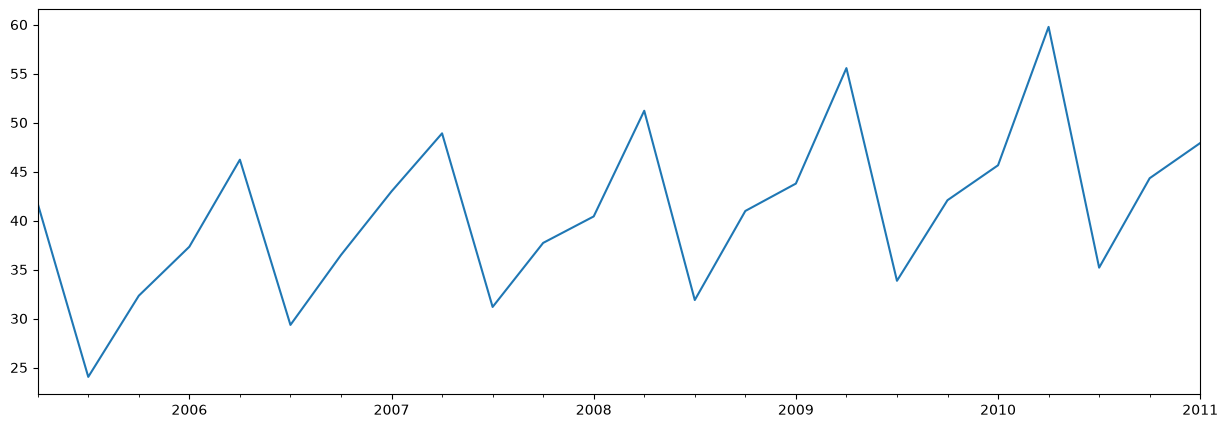

In [20]:
aust.plot()

How could you find the periodicity for this data? 

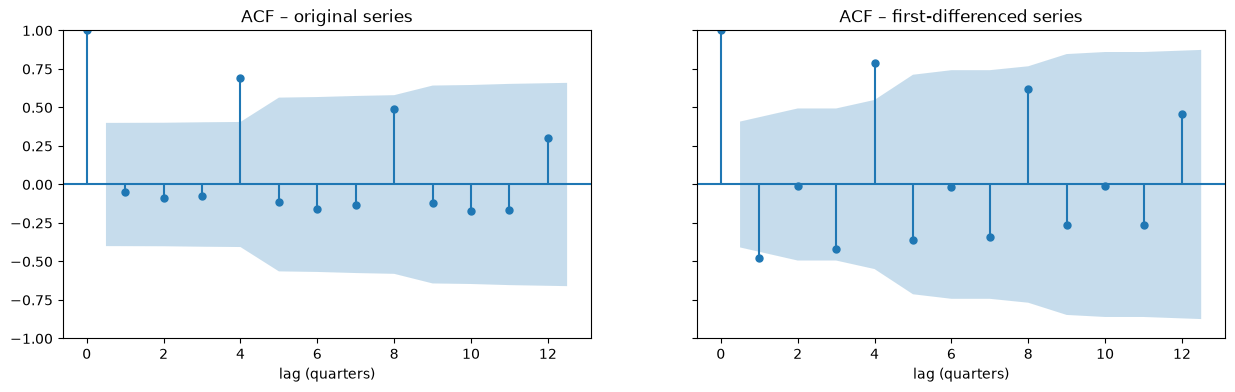

In [21]:
from statsmodels.graphics.tsaplots import plot_acf

fig, axes = plt.subplots(1, 2, figsize=(15, 4), sharey=True)
plot_acf(aust, lags=12, ax=axes[0], title="ACF – original series")
plot_acf(aust.diff().dropna(), lags=12, ax=axes[1], title="ACF – first-differenced series")
for ax in axes:
    ax.set_xlabel("lag (quarters)")
plt.show()

The following cell fit a Holtâ€™s Winters Seasonal model. What does mean these parameters?

In [22]:
fit3 = ExponentialSmoothing(
    aust,
    seasonal_periods = 4,
    trend = "add",
    seasonal = "add",
    use_boxcox = False,
    initialization_method = "estimated",
).fit()

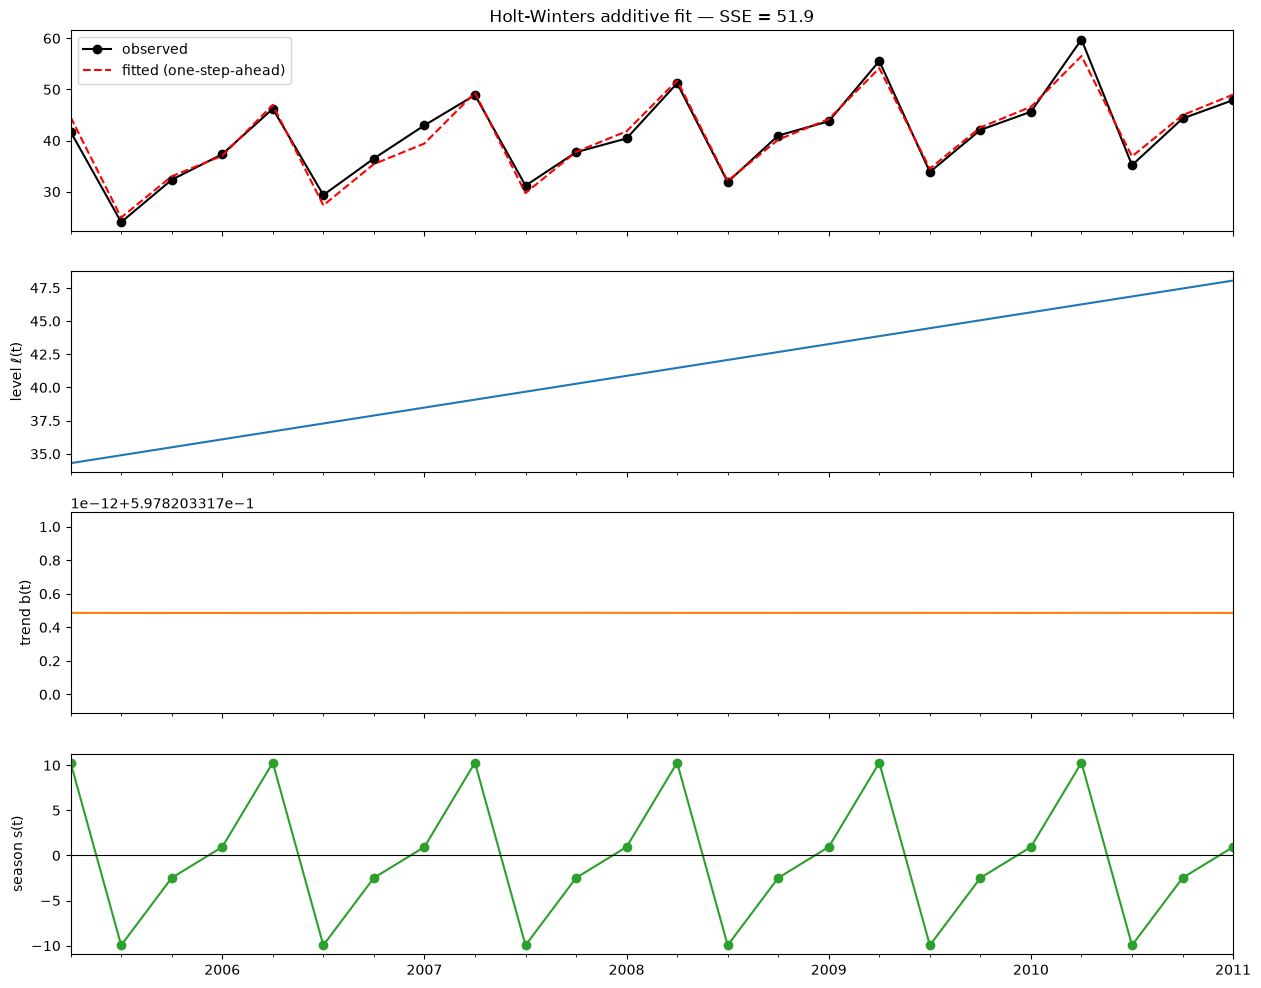

alpha (level)    = 0.0000
beta  (trend)    = 0.0000
gamma (seasonal) = 0.0000
initial seasonal factors: [10.29 -9.96 -2.49  0.94]


In [23]:
fig, axes = plt.subplots(4, 1, figsize=(15, 12), sharex=True)

# Observed vs one-step-ahead fitted values
aust.plot(ax=axes[0], marker="o", color="black", label="observed")
fit3.fittedvalues.plot(ax=axes[0], style="--", color="red", label="fitted (one-step-ahead)")
axes[0].set_title(f"Holt-Winters additive fit — SSE = {fit3.sse:.1f}")
axes[0].legend()

# Estimated components
fit3.level.plot(ax=axes[1], color="tab:blue")
axes[1].set_ylabel("level ℓ(t)")
fit3.trend.plot(ax=axes[2], color="tab:orange")
axes[2].set_ylabel("trend b(t)")
fit3.season.plot(ax=axes[3], color="tab:green", marker="o")
axes[3].set_ylabel("season s(t)")
axes[3].axhline(0, color="black", linewidth=0.8)

plt.show()

# Optimized smoothing parameters and initial seasonal factors
print(f"alpha (level)    = {fit3.params['smoothing_level']:.4f}")
print(f"beta  (trend)    = {fit3.params['smoothing_trend']:.4f}")
print(f"gamma (seasonal) = {fit3.params['smoothing_seasonal']:.4f}")
print("initial seasonal factors:", fit3.params["initial_seasons"].round(2))

Forecast the time series for ten time steps. Plot the results.

In [26]:
forecast3 = fit3.forecast(10)

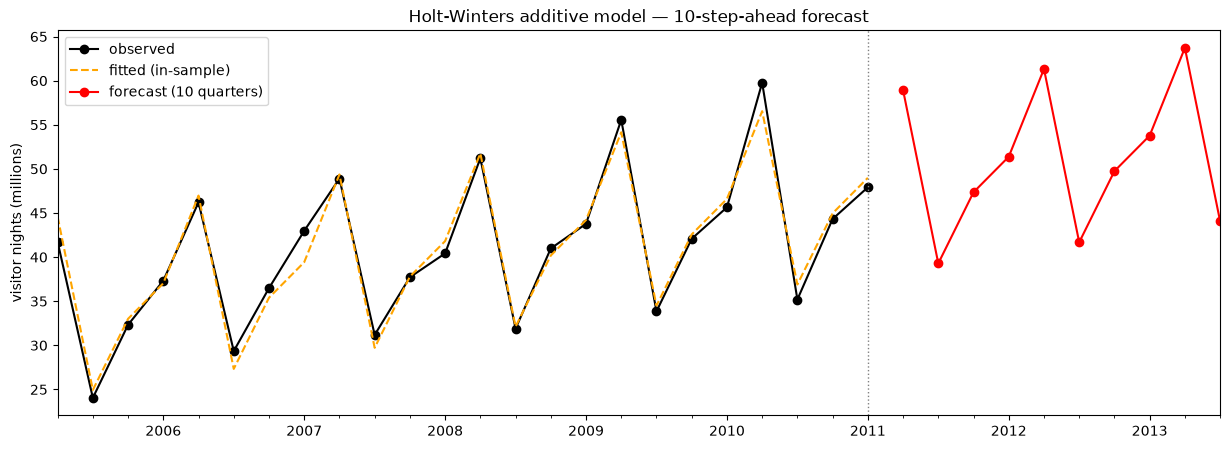

2011-01-01    58.9
2011-04-01    39.3
2011-07-01    47.4
2011-10-01    51.4
2012-01-01    61.3
2012-04-01    41.7
2012-07-01    49.7
2012-10-01    53.8
2013-01-01    63.7
2013-04-01    44.1
Freq: QS-OCT, dtype: float64

In [27]:
fig, ax = plt.subplots()

aust.plot(ax=ax, marker="o", color="black", label="observed")
fit3.fittedvalues.plot(ax=ax, style="--", color="orange", label="fitted (in-sample)")
forecast3.plot(ax=ax, marker="o", color="red", label="forecast (10 quarters)")

# Mark where the observed data end and the forecast begins
ax.axvline(aust.index[-1], color="gray", linestyle=":", linewidth=1)

ax.set_ylabel("visitor nights (millions)")
ax.set_title("Holt-Winters additive model — 10-step-ahead forecast")
ax.legend(loc="upper left")
plt.show()

forecast3.round(1)